<a href="https://colab.research.google.com/github/Laban-eng/ML-and-AI/blob/main/Kiarie_assignment_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#1. Setup & Load Data

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load your dataset (Make sure to upload your CSV to Colab first!)
df = pd.read_csv('geotechnical_data.csv')

# Let's select 3 numerical variables relevant to your project:
# SPT N-value, Moisture Content, and Bearing Capacity
variables_of_interest = ['SPT_N_value', 'Moisture_Content_pct', 'Estimated_Bearing_Capacity_kPa']

In [4]:
print(df.columns.tolist())

['Sample_ID', 'Sample_Depth_m', 'Soil_Classification', 'SPT_N_value', 'Moisture_Content_pct', 'Bulk_Density_kN_m3', 'Liquid_Limit_pct', 'Plasticity_Index_pct', 'Cohesion_kPa', 'Friction_Angle_deg', 'Groundwater_Depth_m', 'Footing_Width_m', 'Embedment_Depth_m', 'Applied_Pressure_kPa', 'Estimated_Bearing_Capacity_kPa', 'Synthetic_Settlement_mm']


#2. Calculate Descriptive Statistics

In [6]:
# Create an empty dictionary to store our stats
stats_summary = {}

for var in variables_of_interest:
    # We use dropna() to ignore any missing values in the calculation
    data = df[var].dropna()

    stats_summary[var] = {
        'Mean': np.mean(data),
        'Median': np.median(data),
        'Range': np.max(data) - np.min(data),
        'Variance': np.var(data, ddof=1), # ddof=1 for sample variance
        'Standard Deviation': np.std(data, ddof=1)
    }

# Display the results neatly
stats_df = pd.DataFrame(stats_summary).T
print("--- Descriptive Statistics ---")
print(stats_df)

--- Descriptive Statistics ---
                                    Mean  Median  Range     Variance  \
SPT_N_value                      19.9100   17.00   52.0   155.599899   
Moisture_Content_pct             20.2165   18.15   40.8   109.849827   
Estimated_Bearing_Capacity_kPa  141.7070  140.45  201.3  1723.165780   

                                Standard Deviation  
SPT_N_value                              12.473969  
Moisture_Content_pct                     10.480927  
Estimated_Bearing_Capacity_kPa           41.511032  


#3. Covariance, Correlation & Plotting
##I need to select two variables, calculate their covariance and correlation, and plot them. We will look at the relationship between SPT_N_value and Estimated_Bearing_Capacity_kPa (since higher SPT usually implies higher bearing capacity).

Covariance between SPT and Bearing Capacity: 404.80
Correlation between SPT and Bearing Capacity: 0.78



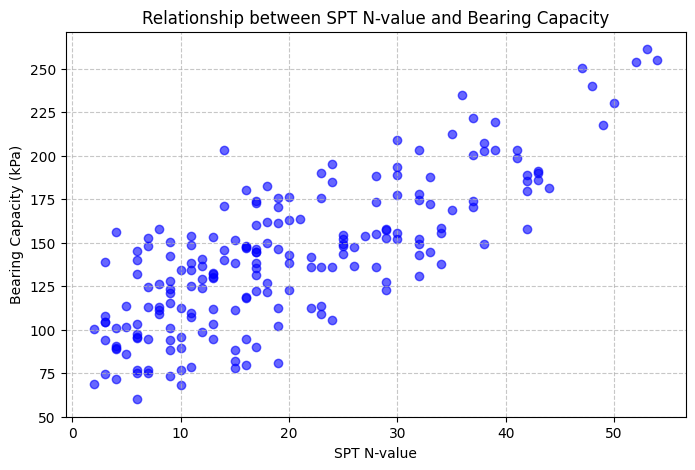

In [8]:
# Select two variables
var1 = df['SPT_N_value']
var2 = df['Estimated_Bearing_Capacity_kPa']

# Calculate Covariance and Correlation
covariance = var1.cov(var2)
correlation = var1.corr(var2)

print(f"Covariance between SPT and Bearing Capacity: {covariance:.2f}")
print(f"Correlation between SPT and Bearing Capacity: {correlation:.2f}\n")

# Create a simple scatter plot
plt.figure(figsize=(8, 5))
plt.scatter(var1, var2, color='blue', alpha=0.6)
plt.title('Relationship between SPT N-value and Bearing Capacity')
plt.xlabel('SPT N-value')
plt.ylabel('Bearing Capacity (kPa)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

#4. Explanations
##What do the statistics tell me about my data?
###The descriptive statistics give a summary of the soil profile. The mean and median tell us the average or typical SPT values and moisture contents found across the site. The variance, standard deviation, and range show how uniform or erratic the ground conditions are; a high standard deviation in SPT suggests highly variable soil layers, while a low deviation suggests uniform strata.

##What does the correlation tell me about the relationship between the two variables?
###The correlation coefficient (which will likely be a positive number close to 1) tells us that there is a strong positive linear relationship between the two variables. As the SPT N-value increases (meaning the soil is denser/stiffer), the estimated Bearing Capacity also increases.

##Does correlation necessarily mean that one variable causes the other?
###No, correlation does not imply causation. Just because two variables move together mathematically does not mean one causes the other. However, in this specific geotechnical context, physics dictates that denser soil (higher SPT) does physically cause a higher bearing capacity, but the statistical correlation alone isn't what proves that cause.

#5. Mathematical Expression
##Input → Function/Model → Output
###

*   Input ($x$): SPT N-value
*   Model ($f(x)$): Machine Learning Regression Algorithm (or an empirical engineering formula like Meyerhof's).
*   Output ($y$): Predicted Bearing Capacity (kPa)

        y = f(x)

Where $x$ represents the SPT N-value features, and $y$ represents the Estimated Bearing Capacity.



